# Deliverable 2: regularising the feed-forward network (11 genres)

The final network of `04_02_feed_forward_genre` (try 7: 4 x 4 average pooling, then 256-128, Adam, learning rate 1e-4)
learns the training images by heart: in the first regularisation notebook, after 13 epochs, it reached about 82 % on the
training images but only about 26 % on validation. This notebook tests the tools of the course against over-fitting
(S06, *"the first fix is always more data. When we cannot, we regularise"*), **one at a time**, on that same network.

| Tool (S06) | Idea (S06) | What we test |
|---|---|---|
| Weight decay (L2) | keep the weights small | AdamW, four values of λ |
| Dropout | do not rely on any single neuron | p = 0.1, 0.3, 0.5 |
| Batch norm | keep each layer's inputs well scaled | `nn.BatchNorm1d` after each hidden `nn.Linear` |
| Early stopping | stop at the best validation epoch | patience of 5 epochs on the validation loss, best weights restored |

Same rules as every notebook of the team: same data split, same seed, same network, **one change at a time**,
every choice made on the validation set, the test set used **once**, at the end.

### What changes compared with the first regularisation notebook (`06_regularization`)

| Before | Now | Why |
|---|---|---|
| 13 epochs (best epoch of the network *without* regularisation) | 30 epochs for every run, best epoch read on validation | regularisation slows down memorisation, so its best epoch comes later: stopping at 13 penalises it |
| `Adam(weight_decay=1e-4)` | `AdamW`, λ from 0.01 to 10 | with Adam the L2 term is divided by Adam's per-weight scale, so it is not a real decay; AdamW applies $w \leftarrow (1-\eta\lambda)\,w$ (S06) |
| one value per tool | a small grid per tool | one value cannot show that a tool does not work |
| no batch norm | tested | one of the S06 tools |
| early stopping only mentioned | implemented (patience, best weights restored) | TP06, exercise 10 |
| no test score for the recommended network | the final network is measured once on test | same protocol as `04_02` |

The same notebook for the 27 styles is `05_01_regularization_style`.

| Part | What we do |
|---|---|
| 0 | Setup and data (the team's shared pipeline) |
| 1 | One network builder with two switches: dropout and batch norm |
| 2 | Training protocol and sanity checks |
| 3 | Reference: try 7 again, for 30 epochs |
| 4 | Weight decay: Adam versus AdamW, four values of λ |
| 5 | Dropout: three rates |
| 6 | Batch normalisation |
| 7 | Comparison of all the runs |
| 8 | Early stopping, choice of the final network, test (once) and cost for the kiosk |

## 0. Setup

In [1]:
import copy
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

sys.path.insert(0, "../src")  # so that "import museum_guide" finds the team's code

# Our own package: the same data pipeline and training functions for every model
from museum_guide.data import prepare_subset
from museum_guide.training import count_parameters, evaluate, fit

# Fix the random seed so that every run gives the same results
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load, split, standardise and batch the genre subset (takes about a minute)
genre = prepare_subset("genre")
n_classes = len(genre["classes"])
print("device:", device, "| classes:", n_classes, "| train batches:", len(genre["train_loader"]))

N_EPOCHS = 30          # same budget as the eight tries of 04_02, for every run of this notebook
LEARNING_RATE = 1e-4   # learning rate of try 7, unchanged
loss_fn = nn.CrossEntropyLoss()

ROOT = Path("..")
FIG_DIR = ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "results"

device: cpu | classes: 11 | train batches: 37


## 1. One network builder for every experiment

The network is the one of try 7 (`04_02`). We add two switches, **off by default**, so that the default network is
exactly try 7. Inside each hidden block the order is:

`nn.Linear` → `nn.BatchNorm1d` (if switched on) → `nn.ReLU` → `nn.Dropout` (if p > 0)

- Batch norm normalises the output of the linear layer, *before* the activation, as in S06.
- Dropout comes after the activation, as in TP06: it switches off whole neurons.
- The output layer stays a plain `nn.Linear`: one logit per class, no dropout and no batch norm on the logits.

In [2]:
def make_mlp(n_classes, image_shape=(3, 32, 32), hidden_sizes=(256, 128), dropout=0.0, batch_norm=False):
    """Build a feed-forward network (MLP) for colour images, with optional dropout and batch norm.

    Args:
        n_classes: number of classes to predict (11 genres or 27 styles).
        image_shape: shape of one input image, (channels, height, width).
        hidden_sizes: number of neurons of each hidden layer.
        dropout: probability of switching off each hidden neuron during training (0 = no dropout).
        batch_norm: if True, add nn.BatchNorm1d after each hidden nn.Linear.

    Returns:
        An nn.Sequential that maps a batch (B, C, H, W) to (B, n_classes) logits.
    """
    # Turn each image into a vector: (B, 3, 32, 32) -> (B, 3072)
    layers = [nn.Flatten()]
    n_in = image_shape[0] * image_shape[1] * image_shape[2]
    for n_out in hidden_sizes:
        layers.append(nn.Linear(n_in, n_out))
        if batch_norm:
            layers.append(nn.BatchNorm1d(n_out))  # normalise each neuron over the mini-batch (S06)
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))    # switch off each neuron with probability p (S06)
        n_in = n_out
    # Output layer: one score (logit) per class, no softmax since CrossEntropyLoss applies it
    layers.append(nn.Linear(n_in, n_classes))
    model = nn.Sequential(*layers)

    # He initialisation, recommended for ReLU networks (TP05 Part D)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model


def make_pooled_mlp(n_classes, pool_size=4, hidden_sizes=(256, 128), dropout=0.0, batch_norm=False):
    """Average pooling followed by the network of make_mlp, as in try 7 of 04_02.

    Returns:
        An nn.Sequential that maps a batch (B, 3, 128, 128) to (B, n_classes) logits.
    """
    pooled_side = 128 // pool_size  # for example 128 // 4 = 32
    return nn.Sequential(
        nn.AvgPool2d(pool_size),     # each block of pool_size x pool_size pixels -> its mean, no weight to learn
        make_mlp(n_classes, (3, pooled_side, pooled_side), hidden_sizes, dropout, batch_norm),
    )


# Check: the default network has the 821,003 parameters of try 7 (04_02)
print("try 7          :", f"{count_parameters(make_pooled_mlp(n_classes)):,} parameters")
print("with dropout   :", f"{count_parameters(make_pooled_mlp(n_classes, dropout=0.3)):,} parameters (dropout has no weight)")
print("with batch norm:", f"{count_parameters(make_pooled_mlp(n_classes, batch_norm=True)):,} parameters "
      "(+ 2 per hidden neuron: scale gamma and shift beta)")
print(make_pooled_mlp(n_classes, dropout=0.3, batch_norm=True))

try 7          : 821,003 parameters
with dropout   : 821,003 parameters (dropout has no weight)
with batch norm: 821,771 parameters (+ 2 per hidden neuron: scale gamma and shift beta)
Sequential(
  (0): AvgPool2d(kernel_size=4, stride=4, padding=0)
  (1): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=256, bias=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=128, out_features=11, bias=True)
  )
)


## 2. Training protocol and sanity checks

Every run starts from the same initial weights (seed 0) and sees the mini-batches in the same order, and only **one**
setting changes. The optimiser is **AdamW** for every run. With $\lambda = 0$, AdamW does exactly the same steps as Adam,
so the reference run is exactly try 7 of `04_02`.

Every run lasts 30 epochs: we read the whole curves (S06: *"overfitting is read on the curves: train loss down,
validation loss up. Always plot both"*) and keep, for each run, the epoch with the best validation accuracy, as in `04_02`.

In [3]:
runs = {}     # name of the run -> history returned by fit
configs = {}  # name of the run -> settings, to retrain the chosen one at the end


def train_run(name, dropout=0.0, batch_norm=False, weight_decay=0.0, decoupled=True, n_epochs=N_EPOCHS):
    """Build a fresh try-7 network with the given settings and train it, like train_genre_pooled_mlp in 04_02.

    Args:
        name: name of the run, used in the summary tables.
        dropout, batch_norm: switches of make_pooled_mlp.
        weight_decay: lambda of the L2 regularisation (0 = none).
        decoupled: True for AdamW (real weight decay), False for Adam (L2 added to the gradient).
        n_epochs: number of epochs.

    Returns:
        (model, history): the trained network and the history returned by fit.
    """
    torch.manual_seed(0)  # same initial weights and same order of the mini-batches for every run
    model = make_pooled_mlp(n_classes, dropout=dropout, batch_norm=batch_norm).to(device)
    optimiser_class = torch.optim.AdamW if decoupled else torch.optim.Adam
    optimizer = optimiser_class(model.parameters(), lr=LEARNING_RATE, weight_decay=weight_decay)
    print(f"--- {name} ---")
    history = fit(model, genre["train_loader"], genre["val_loader"], loss_fn, optimizer, n_epochs, device=device)
    runs[name] = history
    configs[name] = {"dropout": dropout, "batch_norm": batch_norm, "weight_decay": weight_decay, "decoupled": decoupled}
    return model, history


def summarise(names):
    """One row per run: best validation accuracy, its epoch, lowest validation loss and final training accuracy."""
    rows = []
    for name in names:
        h = runs[name]
        best_acc = max(h["val_acc"])
        rows.append({
            "run": name,
            "best epoch": h["val_acc"].index(best_acc) + 1,
            "best val accuracy": round(best_acc, 3),
            "lowest val loss": round(min(h["val_loss"]), 3),
            "epoch of lowest val loss": h["val_loss"].index(min(h["val_loss"])) + 1,
            "train accuracy, last epoch": round(h["train_acc"][-1], 3),
        })
    return pd.DataFrame(rows).set_index("run")


def plot_history(history, title=""):
    """Plot the loss and accuracy curves of one run, train versus validation, as in 04_02."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].legend()
    axes[1].plot(epochs, history["train_acc"], label="train")
    axes[1].plot(epochs, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title)
    plt.show()


def plot_compare(names, title="", file_name=None):
    """Validation loss and validation accuracy of several runs on the same axes."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for name in names:
        h = runs[name]
        epochs = range(1, len(h["val_loss"]) + 1)
        axes[0].plot(epochs, h["val_loss"], label=name)
        axes[1].plot(epochs, h["val_acc"], label=name)
    axes[0].set(xlabel="epoch", ylabel="validation loss")
    axes[1].set(xlabel="epoch", ylabel="validation accuracy")
    axes[1].axhline(1 / n_classes, ls=":", c="k", label="chance")
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[1].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    if file_name:
        fig.savefig(FIG_DIR / file_name, dpi=150)  # saved for the slides
    plt.show()

**Sanity checks before training (S06).**

1. An untrained network that knows nothing predicts $1/C$ everywhere, so its loss is about $\ln C = \ln 11 = 2.40$.
2. Dropout and batch norm behave differently in training and in evaluation: in `model.train()` dropout switches neurons
   off at random, in `model.eval()` it is off. We check that `evaluate` (shared code) puts the network in evaluation mode:
   two evaluations of a network with dropout must give exactly the same loss.

In [4]:
torch.manual_seed(0)
check_model = make_pooled_mlp(n_classes, dropout=0.5).to(device)

# 1. Initial loss close to ln(C)
initial_loss, initial_acc = evaluate(check_model, genre["val_loader"], loss_fn, device=device)
print(f"initial validation loss {initial_loss:.3f} (ln {n_classes} = {math.log(n_classes):.3f}) "
      f"| accuracy {initial_acc:.3f} (chance {1 / n_classes:.3f})")

# 2. Dropout is random in train mode and switched off in evaluation mode
xb, _ = next(iter(genre["val_loader"]))
xb = xb[:8].to(device)
check_model.train()
print("train mode, two passes identical:", torch.equal(check_model(xb), check_model(xb)), "(expected False)")
check_model.eval()
with torch.no_grad():
    print("eval mode,  two passes identical:", torch.equal(check_model(xb), check_model(xb)), "(expected True)")

check_model.train()  # leave it in train mode: evaluate must switch to eval mode by itself
loss_a, _ = evaluate(check_model, genre["val_loader"], loss_fn, device=device)
loss_b, _ = evaluate(check_model, genre["val_loader"], loss_fn, device=device)
print("evaluate gives the same loss twice:", loss_a == loss_b, "(expected True: evaluate calls model.eval())")

initial validation loss 2.996 (ln 11 = 2.398) | accuracy 0.113 (chance 0.091)
train mode, two passes identical: False (expected False)
eval mode,  two passes identical: True (expected True)
evaluate gives the same loss twice: True (expected True: evaluate calls model.eval())


## 3. Reference: try 7 again, for 30 epochs

No regularisation. With the same seed, the first 13 epochs must be exactly those of try 7 in `04_02`
(validation accuracy 0.266 at epoch 13).

--- reference (try 7) ---
epoch  1 | train loss 2.037 acc 0.292 | val loss 2.262 acc 0.218 | 2.4 s
epoch  2 | train loss 1.822 acc 0.385 | val loss 2.229 acc 0.236 | 0.4 s
epoch  3 | train loss 1.676 acc 0.459 | val loss 2.221 acc 0.234 | 0.4 s
epoch  4 | train loss 1.557 acc 0.522 | val loss 2.212 acc 0.254 | 0.4 s
epoch  5 | train loss 1.455 acc 0.573 | val loss 2.206 acc 0.252 | 0.5 s
epoch  6 | train loss 1.340 acc 0.623 | val loss 2.205 acc 0.236 | 0.5 s
epoch  7 | train loss 1.264 acc 0.656 | val loss 2.225 acc 0.266 | 0.3 s
epoch  8 | train loss 1.171 acc 0.703 | val loss 2.226 acc 0.250 | 0.3 s
epoch  9 | train loss 1.103 acc 0.728 | val loss 2.234 acc 0.250 | 0.4 s
epoch 10 | train loss 1.052 acc 0.755 | val loss 2.291 acc 0.226 | 0.5 s
epoch 11 | train loss 0.975 acc 0.786 | val loss 2.288 acc 0.242 | 0.5 s
epoch 12 | train loss 0.908 acc 0.810 | val loss 2.290 acc 0.236 | 0.4 s
epoch 13 | train loss 0.868 acc 0.816 | val loss 2.315 acc 0.250 | 0.5 s
epoch 14 | train loss 0.8

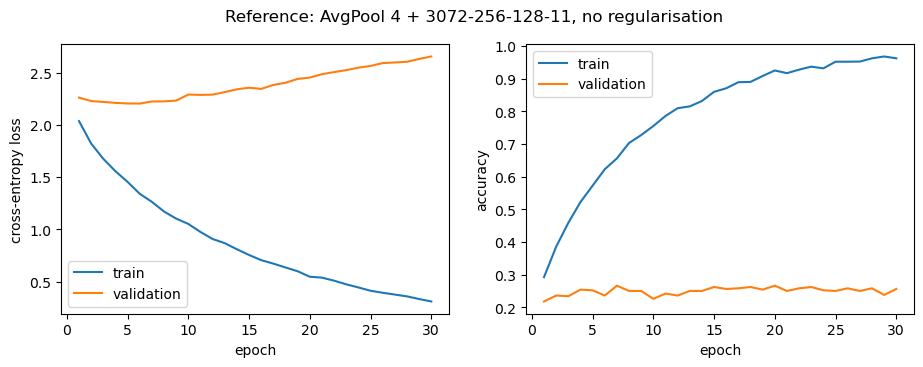

In [5]:
reference_model, reference_history = train_run("reference (try 7)")
print(f"validation accuracy at epoch 13: {reference_history['val_acc'][12]:.3f} (04_02, try 7: 0.266)")
plot_history(reference_history, "Reference: AvgPool 4 + 3072-256-128-11, no regularisation")

**Reading.** The reference shows the over-fitting pattern of S06: the training loss falls all the way (2.04 → 0.31, training accuracy 29 % → 96 %), while the validation loss reaches its minimum at epoch 6 (2.205) and then rises steadily to 2.66 at epoch 30. From epoch 6 on, the network learns details of the training images that do not generalise.

The validation accuracy, on the other hand, stays flat between 0.22 and 0.27 for the whole run (best 0.266, at epochs 7 and 20). The rising validation loss does not mean more mistakes: the network becomes more and more confident in its wrong answers, which the cross-entropy punishes. At epoch 30 the gap between training and validation accuracy is about 70 points: this is what the next parts try to reduce.

## 4. Weight decay (L2)

**The idea (S06).** We add a penalty on large weights to the cost: $J_{reg}(W) = J(W) + \frac{\lambda}{2}\lVert W\rVert^2$.
Its gradient is $\lambda w$, so each update becomes

$$w \leftarrow (1-\eta\lambda)\,w - \eta\,\frac{\partial J}{\partial w}$$

At every step the weight is first multiplied by $1-\eta\lambda$, slightly below 1 (it *decays* towards 0), then the usual
step is applied. A weight that the data do not need shrinks to 0; a useful weight is kept by its gradient.

**Adam or AdamW?** `torch.optim.Adam(weight_decay=λ)` adds $\lambda w$ to the gradient, and Adam then divides every gradient
by its own running scale $\sqrt{v}$: the weights with large gradients are hardly decayed at all. This is no longer the
update above. `torch.optim.AdamW` applies the decay $(1-\eta\lambda)$ directly, outside Adam's scaling: this is the
*"decoupled version, for Adam"* of S06.

**Which values of λ?** With AdamW the decay of one step is $\eta\lambda$, and here $\eta = 10^{-4}$. The cell below computes
what is left, after the 30 epochs, of a weight that the data do not need ($(1-\eta\lambda)^{\text{steps}}$). This tells us
which values can have an effect at all.

In [10]:
WD_GRID = [0.01, 0.1, 1.0, 10.0, 30.0, 100.0]
n_steps = N_EPOCHS * len(genre["train_loader"])  # number of updates in 30 epochs
print(f"{n_steps} updates in {N_EPOCHS} epochs, learning rate {LEARNING_RATE:g}")
for lam in WD_GRID:
    left = (1 - LEARNING_RATE * lam) ** n_steps
    print(f"lambda = {lam:<5g} decay per step {LEARNING_RATE * lam:.0e} -> an unused weight keeps {left:.1%} of its value")

1110 updates in 30 epochs, learning rate 0.0001
lambda = 0.01  decay per step 1e-06 -> an unused weight keeps 99.9% of its value
lambda = 0.1   decay per step 1e-05 -> an unused weight keeps 98.9% of its value
lambda = 1     decay per step 1e-04 -> an unused weight keeps 89.5% of its value
lambda = 10    decay per step 1e-03 -> an unused weight keeps 32.9% of its value
lambda = 30    decay per step 3e-03 -> an unused weight keeps 3.6% of its value
lambda = 100   decay per step 1e-02 -> an unused weight keeps 0.0% of its value


With $\eta = 10^{-4}$, $\lambda = 0.01$ (the usual default) changes almost nothing; this is also why the value $10^{-4}$ of the
first notebook could not have any visible effect. We therefore test four values, from "almost nothing" to
"strong enough to under-fit". We also run again the setting of the first notebook (Adam, $\lambda = 10^{-4}$), now for 30
epochs, to compare.

--- Adam + L2 1e-4 (first notebook) ---
epoch  1 | train loss 2.036 acc 0.294 | val loss 2.263 acc 0.218 | 1.0 s
epoch  2 | train loss 1.828 acc 0.382 | val loss 2.241 acc 0.226 | 0.5 s
epoch  3 | train loss 1.679 acc 0.459 | val loss 2.227 acc 0.238 | 2.1 s
epoch  4 | train loss 1.561 acc 0.510 | val loss 2.217 acc 0.246 | 0.5 s
epoch  5 | train loss 1.452 acc 0.573 | val loss 2.213 acc 0.240 | 0.4 s
epoch  6 | train loss 1.345 acc 0.621 | val loss 2.216 acc 0.246 | 0.4 s
epoch  7 | train loss 1.266 acc 0.653 | val loss 2.229 acc 0.270 | 0.3 s
epoch  8 | train loss 1.173 acc 0.702 | val loss 2.234 acc 0.254 | 0.3 s
epoch  9 | train loss 1.109 acc 0.727 | val loss 2.246 acc 0.260 | 0.3 s
epoch 10 | train loss 1.049 acc 0.759 | val loss 2.290 acc 0.232 | 0.4 s
epoch 11 | train loss 0.979 acc 0.790 | val loss 2.295 acc 0.226 | 0.3 s
epoch 12 | train loss 0.912 acc 0.796 | val loss 2.300 acc 0.242 | 0.3 s
epoch 13 | train loss 0.873 acc 0.810 | val loss 2.332 acc 0.276 | 0.8 s
epoch 14 | 

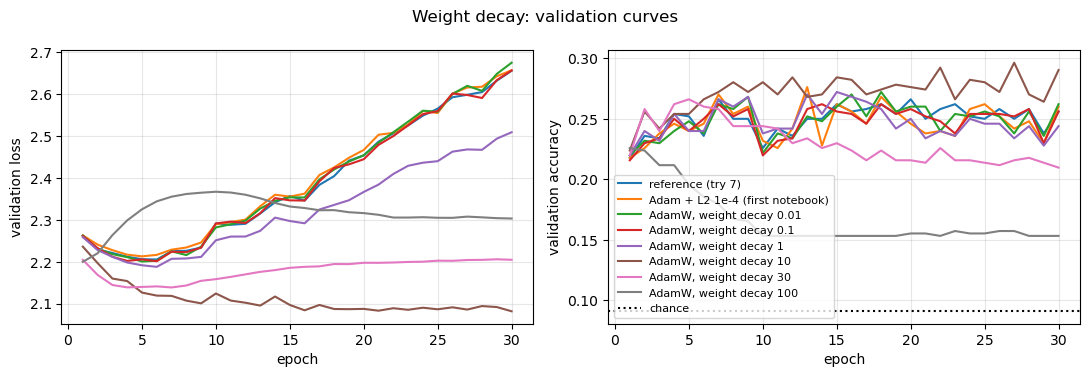

,best epoch,best val accuracy,lowest val loss,epoch of lowest val loss,"train accuracy, last epoch"
run,,,,,
reference (try 7),7,0.266,2.205,6,0.963
Adam + L2 1e-4 (first notebook),13,0.276,2.213,5,0.962
"AdamW, weight decay 0.01",18,0.272,2.200,5,0.960
"AdamW, weight decay 0.1",7,0.262,2.201,6,0.961
"AdamW, weight decay 1",15,0.272,2.188,6,0.946
"AdamW, weight decay 10",27,0.296,2.081,30,0.569
"AdamW, weight decay 30",5,0.266,2.138,7,0.225
"AdamW, weight decay 100",1,0.226,2.200,1,0.149


In [11]:
train_run("Adam + L2 1e-4 (first notebook)", weight_decay=1e-4, decoupled=False)
for lam in WD_GRID:
    train_run(f"AdamW, weight decay {lam:g}", weight_decay=lam)

wd_names = ["reference (try 7)", "Adam + L2 1e-4 (first notebook)"] + [f"AdamW, weight decay {lam:g}" for lam in WD_GRID]
plot_compare(wd_names, "Weight decay: validation curves", "reg_genre_weight_decay.png")
summarise(wd_names)

**Reading.** The decay computed above predicts the result. With λ = 0.01 and 0.1 (and with Adam + L2 1e-4, the setting of the first notebook), an unused weight keeps 99 % of its value: the curves are on top of the reference (lowest validation loss at epoch 5–6, then a rise to 2.66; 96 % training accuracy). The 0.276 of Adam + L2 is a single spike at epoch 13 (0.228 at epoch 14): noise. The weight decay of the first notebook was too small to have any effect.

With λ = 1 the validation loss rises more slowly (2.51 at epoch 30 instead of 2.66), but the best accuracy (0.272) is within the noise. With λ = 10 the weight decay really regularises: the validation loss no longer rises (2.08 at epoch 30, the lowest of all runs), the training accuracy drops from 96 % to 57 %, and the validation accuracy stays above the reference at almost every epoch from epoch 10 on, with a best of 0.296 (epoch 27), +3.0 points, about 1.5 standard errors. The evidence is the curve being consistently higher, not a single epoch.

Since λ = 10 was at the edge of the first grid, we extended it. With λ = 30 the network under-fits: training accuracy falls to 22.5 %, and the validation accuracy peaks at 0.266 around epoch 5, then decreases to about 0.21: the weights shrink faster than the data can maintain them (S06: “both losses stay high and close: underfitting”). With λ = 100 it collapses: its best accuracy is at epoch 1 (0.226), then it drops to about 0.155, close to chance, with 15 % training accuracy. λ = 10 is therefore a real optimum, inside the grid: too little decay does nothing, too much destroys what the network learns, the same U-shape as the regularisation C of the logistic regression.

## 5. Dropout

**The idea (S06).** During training, each hidden neuron is switched off (set to 0) with probability $p$, a new random choice
at every mini-batch. The neurons that stay on are multiplied by $1/(1-p)$, so that the expected value of each activation does
not change. The network cannot rely on any single neuron. In `model.eval()` dropout is off and every neuron is used.

We test three rates around the value of the first notebook (0.3).

Careful when reading the table: `fit` measures the training accuracy *during* the epoch, with dropout on. The training
accuracy of a dropout run is therefore measured on a weakened network, and looks lower than the network really is.
The fair comparison is on **validation**, where dropout is off for every run.

--- dropout 0.1 ---
epoch  1 | train loss 2.084 acc 0.271 | val loss 2.282 acc 0.224 | 0.6 s
epoch  2 | train loss 1.896 acc 0.353 | val loss 2.196 acc 0.226 | 0.3 s
epoch  3 | train loss 1.773 acc 0.405 | val loss 2.180 acc 0.240 | 0.3 s
epoch  4 | train loss 1.680 acc 0.465 | val loss 2.177 acc 0.242 | 0.2 s
epoch  5 | train loss 1.580 acc 0.510 | val loss 2.181 acc 0.254 | 0.3 s
epoch  6 | train loss 1.523 acc 0.526 | val loss 2.171 acc 0.254 | 0.2 s
epoch  7 | train loss 1.418 acc 0.579 | val loss 2.179 acc 0.234 | 0.2 s
epoch  8 | train loss 1.367 acc 0.605 | val loss 2.215 acc 0.264 | 0.4 s
epoch  9 | train loss 1.319 acc 0.616 | val loss 2.223 acc 0.252 | 0.3 s
epoch 10 | train loss 1.239 acc 0.661 | val loss 2.206 acc 0.228 | 0.4 s
epoch 11 | train loss 1.183 acc 0.684 | val loss 2.211 acc 0.248 | 0.2 s
epoch 12 | train loss 1.133 acc 0.713 | val loss 2.248 acc 0.252 | 0.3 s
epoch 13 | train loss 1.068 acc 0.734 | val loss 2.219 acc 0.268 | 0.3 s
epoch 14 | train loss 1.027 acc

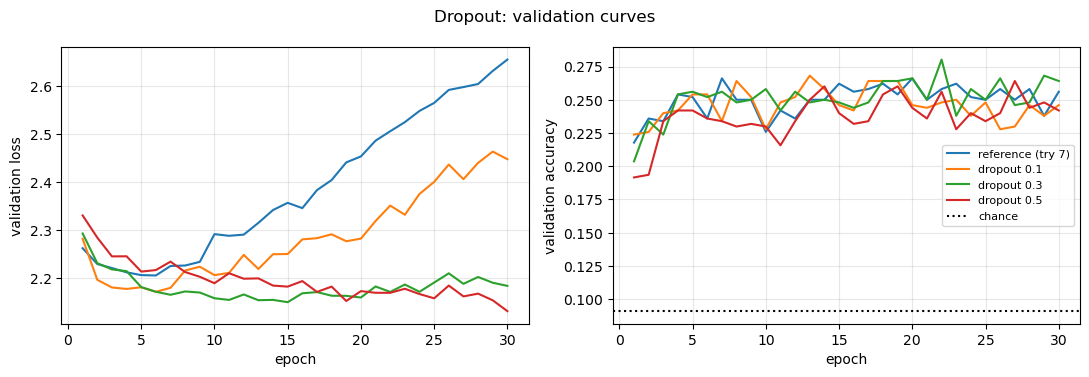

,best epoch,best val accuracy,lowest val loss,epoch of lowest val loss,"train accuracy, last epoch"
run,,,,,
reference (try 7),7,0.266,2.205,6,0.963
dropout 0.1,13,0.268,2.171,6,0.932
dropout 0.3,22,0.280,2.149,15,0.772
dropout 0.5,27,0.264,2.131,30,0.562


In [12]:
DROPOUT_GRID = [0.1, 0.3, 0.5]
for p in DROPOUT_GRID:
    train_run(f"dropout {p:g}", dropout=p)

dropout_names = ["reference (try 7)"] + [f"dropout {p:g}" for p in DROPOUT_GRID]
plot_compare(dropout_names, "Dropout: validation curves", "reg_genre_dropout.png")
summarise(dropout_names)

**Reading.** Dropout has a clear effect on over-fitting, which grows with p. The validation loss of the reference rises from epoch 6 to 2.66; with p = 0.1 it rises later and less (2.45 at epoch 30); with p = 0.3 it stays flat around 2.15–2.20 (lowest 2.149 at epoch 15); with p = 0.5 it is still falling at epoch 30 (2.131). Memorisation drops in the same order: training accuracy at epoch 30 is 96 %, 93 %, 77 % and 56 % (measured by fit with dropout on, so it slightly underestimates the network, but the trend is clear).

The validation accuracy, however, does not improve. The four curves stay mixed between 0.23 and 0.27. The best value, 0.280 for p = 0.3, is a single spike at epoch 22 (0.238 at epoch 23): +1.4 points, less than one standard error. p = 0.5 even starts more slowly (0.19 in the first two epochs), since it learns with half of its neurons switched off.

Dropout makes the network less confident in its wrong answers (lower validation loss), but not better at classifying. Unlike weight decay with λ = 10, no dropout rate keeps the validation accuracy consistently above the reference. The 0.268 of the first notebook (13 epochs) was within the noise as well.

## 6. Batch normalisation

**The idea (S06).** For each neuron, batch norm subtracts the mean and divides by the standard deviation **over the
mini-batch**, then applies a learnt scale $\gamma$ and shift $\beta$ (2 parameters per neuron). The inputs of every layer
stay well scaled during training. In `model.eval()` it uses running averages of the mean and variance computed during
training, so a single kiosk image can be classified. Because each image is normalised with the other images of its
mini-batch, batch norm also adds a little noise during training, which acts as a mild regularisation.

One change only: batch norm after each hidden `nn.Linear`, same learning rate (1e-4) and no dropout.
The training set has 2,309 images, so the last mini-batch has only 2,309 − 36 × 64 = 5 images: batch norm still works
(it needs at least 2), with a noisier estimate on that batch.

--- batch norm ---
epoch  1 | train loss 2.109 acc 0.282 | val loss 2.346 acc 0.196 | 0.6 s
epoch  2 | train loss 1.904 acc 0.358 | val loss 2.261 acc 0.232 | 0.3 s
epoch  3 | train loss 1.772 acc 0.427 | val loss 2.219 acc 0.224 | 0.3 s
epoch  4 | train loss 1.678 acc 0.460 | val loss 2.210 acc 0.254 | 0.3 s
epoch  5 | train loss 1.576 acc 0.522 | val loss 2.200 acc 0.246 | 0.3 s
epoch  6 | train loss 1.461 acc 0.582 | val loss 2.193 acc 0.250 | 0.3 s
epoch  7 | train loss 1.370 acc 0.621 | val loss 2.218 acc 0.246 | 0.3 s
epoch  8 | train loss 1.291 acc 0.668 | val loss 2.202 acc 0.264 | 0.3 s
epoch  9 | train loss 1.212 acc 0.712 | val loss 2.218 acc 0.252 | 0.3 s
epoch 10 | train loss 1.212 acc 0.705 | val loss 2.242 acc 0.246 | 0.3 s
epoch 11 | train loss 1.130 acc 0.731 | val loss 2.266 acc 0.224 | 0.3 s
epoch 12 | train loss 1.034 acc 0.785 | val loss 2.223 acc 0.256 | 0.5 s
epoch 13 | train loss 0.990 acc 0.793 | val loss 2.247 acc 0.248 | 0.3 s
epoch 14 | train loss 0.952 acc 

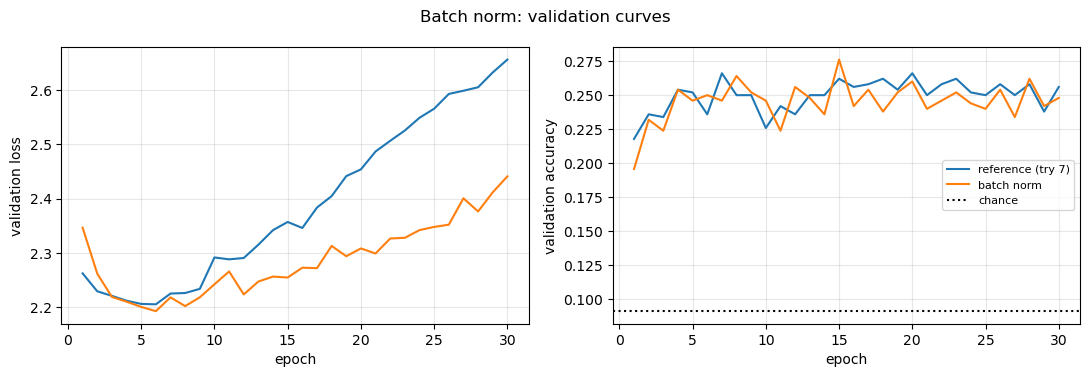

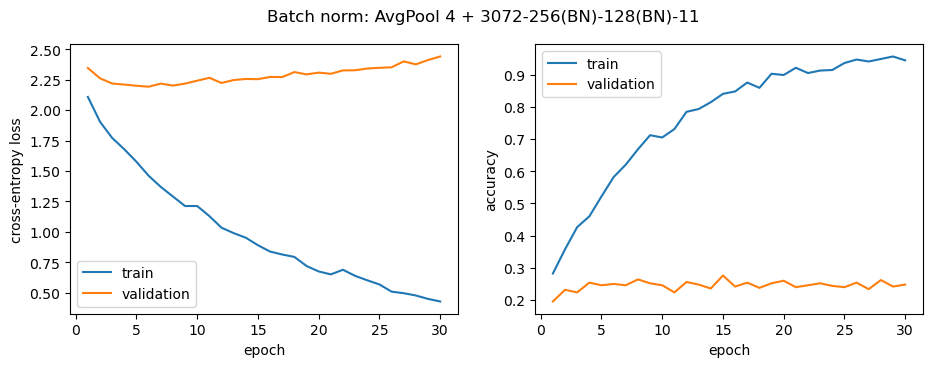

,best epoch,best val accuracy,lowest val loss,epoch of lowest val loss,"train accuracy, last epoch"
run,,,,,
reference (try 7),7,0.266,2.205,6,0.963
batch norm,15,0.276,2.193,6,0.945


In [13]:
train_run("batch norm", batch_norm=True)

bn_names = ["reference (try 7)", "batch norm"]
plot_compare(bn_names, "Batch norm: validation curves", "reg_genre_batch_norm.png")
plot_history(runs["batch norm"], "Batch norm: AvgPool 4 + 3072-256(BN)-128(BN)-11")
summarise(bn_names)

**Reading.** Batch norm has a mild regularising effect. The validation loss reaches its minimum at the same epoch as the reference (epoch 6, 2.193 vs 2.205), but then rises more slowly (2.44 at epoch 30 instead of 2.66): normalising each image with the other images of its mini-batch adds a little noise during training. Memorisation is almost unchanged (94.5 % training accuracy at epoch 30 vs 96.3 %), much less of an effect than dropout 0.3 (77 %) or weight decay λ = 10 (57 %).

Training is not faster either. In S06, batch norm mainly keeps the inputs of each layer well scaled, which matters for deep networks and allows larger learning rates. Our network has only two hidden layers, its inputs are already standardised, and we kept the learning rate at 1e-4 (one change at a time), so there was little to gain.

The validation accuracy does not improve: the best value, 0.276, is a single spike at epoch 15 (0.242 at epoch 16), +1.0 point, within the noise, and after epoch 15 the curve is often slightly below the reference.

## 7. Comparison of all the runs

How big is the noise? With $n$ validation images and an accuracy $p$, the standard error of the measured accuracy is
$\sqrt{p(1-p)/n}$. A difference smaller than this is not evidence that one setting is better.

In [14]:
summary = summarise(list(runs)).sort_values("best val accuracy", ascending=False)
n_val = len(genre["val_idx"])
p_ref = summary.loc["reference (try 7)", "best val accuracy"]
noise = math.sqrt(p_ref * (1 - p_ref) / n_val)
print(f"{n_val} validation images: standard error about {noise:.3f} ({noise * 100:.1f} points)")
summary["gain vs reference (points)"] = ((summary["best val accuracy"] - p_ref) * 100).round(1)
summary

496 validation images: standard error about 0.020 (2.0 points)


,best epoch,best val accuracy,lowest val loss,epoch of lowest val loss,"train accuracy, last epoch",gain vs reference (points)
run,,,,,,
"AdamW, weight decay 10",27,0.296,2.081,30,0.569,3.0
dropout 0.3,22,0.280,2.149,15,0.772,1.4
Adam + L2 1e-4 (first notebook),13,0.276,2.213,5,0.962,1.0
batch norm,15,0.276,2.193,6,0.945,1.0
"AdamW, weight decay 0.01",18,0.272,2.200,5,0.960,0.6
"AdamW, weight decay 1",15,0.272,2.188,6,0.946,0.6
dropout 0.1,13,0.268,2.171,6,0.932,0.2
reference (try 7),7,0.266,2.205,6,0.963,0.0
"AdamW, weight decay 30",5,0.266,2.138,7,0.225,0.0


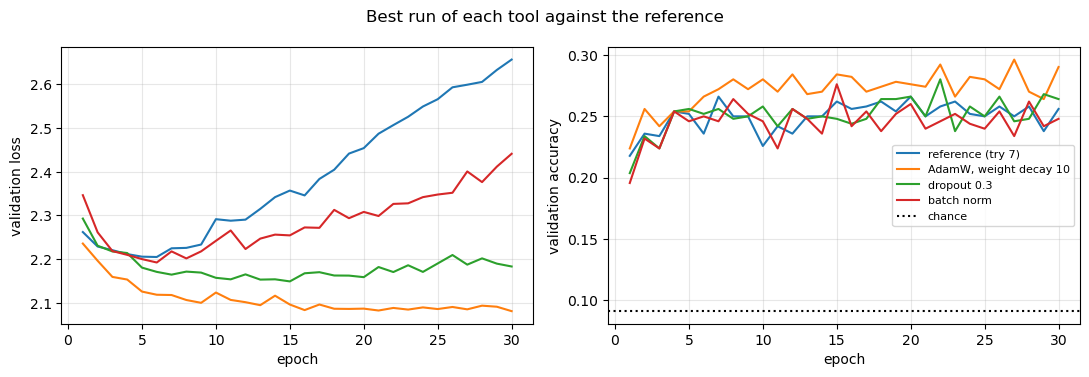

In [15]:
# Best run of each family, against the reference
best_of = lambda names: max(names, key=lambda n: max(runs[n]["val_acc"]))
family_best = ["reference (try 7)",
               best_of([f"AdamW, weight decay {lam:g}" for lam in WD_GRID]),
               best_of([f"dropout {p:g}" for p in DROPOUT_GRID]),
               "batch norm"]
plot_compare(family_best, "Best run of each tool against the reference", "reg_genre_comparison.png")

**Reading.** With 496 validation images, the standard error is about 2.0 points. Only AdamW with λ = 10 beats the reference by more than that: +3.0 points (0.296 vs 0.266). All the other runs are within ±1.4 points, except λ = 100 (−4.0, collapse).

The figure shows the two effects of regularisation. Against over-fitting, weight decay 10 and dropout 0.3 work: their validation loss no longer rises (2.08 and about 2.18 at epoch 30, against 2.66 for the reference), batch norm only slows the rise (2.44). On accuracy, only weight decay 10 stands out: its curve is above the others at almost every epoch from epoch 5 on, whereas dropout and batch norm stay mixed with the reference.

We compared 13 runs, so the best one is slightly favoured by chance; the gain of λ = 10 is still credible because it is consistent over the epochs, not a single spike. Overall, regularisation fixes the memorisation but adds at most about 3 points: on raw pixels, the limit of the MLP is mostly its input.

## 8. Early stopping and the final network

### 8.1 Early stopping

**The idea (S06, TP06 exercise 10).** After each epoch, we measure the validation loss. When it improves we keep a copy of
the weights; when it has not improved for `patience` epochs in a row, we stop and **restore the best weights**. So far we
trained every run for 30 epochs and *read* the best epoch afterwards; early stopping does it during training and returns
the network of the best epoch.

We watch the **validation loss** rather than the accuracy, as in the ResNet notebooks: the loss changes smoothly, while the
accuracy jumps by whole images. Patience: 5 epochs.

The training loop is the five lines of the course (forward, loss, `zero_grad`, `backward`, `step`); after each epoch the
network is measured in evaluation mode with the shared `evaluate`.

In [16]:
def fit_early_stopping(model, train_loader, val_loader, loss_fn, optimizer, max_epochs=N_EPOCHS, patience=5):
    """Train with early stopping on the validation loss, and restore the weights of the best epoch (TP06 Ex. 10).

    Args:
        model, train_loader, val_loader, loss_fn, optimizer: as for fit.
        max_epochs: maximum number of epochs.
        patience: number of epochs without improvement of the validation loss before stopping.

    Returns:
        (history, best_epoch): the history (same keys as fit) and the epoch whose weights were restored.
    """
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    best_loss, best_epoch, best_state, waited = float("inf"), 0, None, 0
    for epoch in range(1, max_epochs + 1):
        start = time.time()
        model.train()  # dropout on, batch norm uses the statistics of each mini-batch
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)               # 1. forward
            loss = loss_fn(logits, yb)       # 2. loss
            optimizer.zero_grad()            # 3. reset the gradients
            loss.backward()                  # 4. backpropagation
            optimizer.step()                 # 5. update
        epoch_time = time.time() - start

        # Measure train and validation in evaluation mode (dropout off, batch norm with running statistics)
        model.eval()
        train_loss, train_acc = evaluate(model, train_loader, loss_fn, device=device)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device=device)
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc, epoch_time]):
            history[key].append(value)
        print(f"epoch {epoch:2d} | train loss {train_loss:.3f} acc {train_acc:.3f} "
              f"| val loss {val_loss:.3f} acc {val_acc:.3f} | {epoch_time:.1f} s")

        if val_loss < best_loss:  # better: keep a copy of these weights
            best_loss, best_epoch, waited = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:                     # not better: wait, and stop after `patience` epochs
            waited += 1
            if waited >= patience:
                print(f"early stop: no improvement of the validation loss for {patience} epochs")
                break

    model.load_state_dict(best_state)  # back to the best epoch
    print(f"best epoch: {best_epoch} (validation loss {best_loss:.3f}), weights restored")
    return history, best_epoch

### 8.2 Choice of the final network (rule written before looking at the test set)

1. Candidate: the run with the best validation accuracy in part 7.
2. We keep its regularisation **only if** it beats the reference by more than one standard error (part 7).
   Otherwise we keep the reference network: when two settings are equal within the noise, the simpler one wins.
3. The chosen network is trained again with early stopping, then measured **once** on the test set.

candidate: AdamW, weight decay 10 (gain +3.0 points, noise 2.0 points) -> chosen: AdamW, weight decay 10
settings: {'dropout': 0.0, 'batch_norm': False, 'weight_decay': 10.0, 'decoupled': True}
epoch  1 | train loss 2.035 acc 0.288 | val loss 2.236 acc 0.224 | 0.8 s
epoch  2 | train loss 1.852 acc 0.388 | val loss 2.197 acc 0.256 | 0.3 s
epoch  3 | train loss 1.754 acc 0.434 | val loss 2.160 acc 0.242 | 0.7 s
epoch  4 | train loss 1.691 acc 0.486 | val loss 2.154 acc 0.254 | 0.3 s
epoch  5 | train loss 1.636 acc 0.523 | val loss 2.126 acc 0.254 | 0.5 s
epoch  6 | train loss 1.597 acc 0.547 | val loss 2.119 acc 0.266 | 0.3 s
epoch  7 | train loss 1.573 acc 0.560 | val loss 2.118 acc 0.272 | 0.2 s
epoch  8 | train loss 1.546 acc 0.591 | val loss 2.107 acc 0.280 | 0.2 s
epoch  9 | train loss 1.535 acc 0.584 | val loss 2.100 acc 0.272 | 0.2 s
epoch 10 | train loss 1.541 acc 0.583 | val loss 2.124 acc 0.280 | 0.3 s
epoch 11 | train loss 1.530 acc 0.613 | val loss 2.107 acc 0.270 | 0.3 s
epo

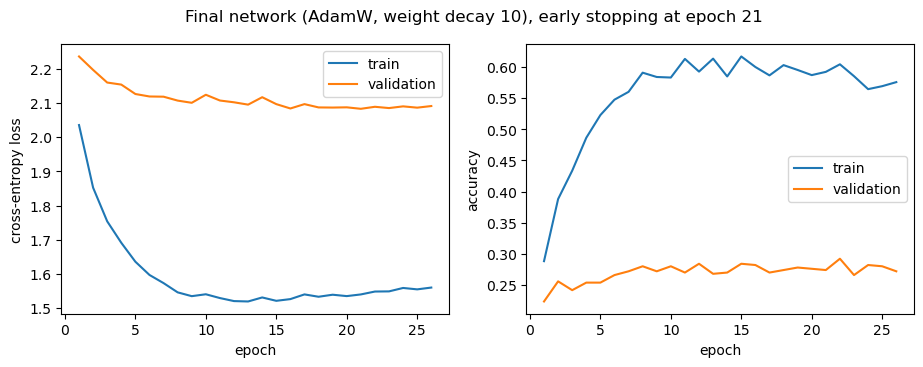

In [17]:
candidate = summary.index[0]
gain = summary.loc[candidate, "best val accuracy"] - p_ref
chosen = candidate if gain > noise else "reference (try 7)"
print(f"candidate: {candidate} (gain {gain * 100:+.1f} points, noise {noise * 100:.1f} points) -> chosen: {chosen}")
chosen_config = configs[chosen]
print("settings:", chosen_config)

torch.manual_seed(0)
final_model = make_pooled_mlp(n_classes, dropout=chosen_config["dropout"],
                              batch_norm=chosen_config["batch_norm"]).to(device)
optimiser_class = torch.optim.AdamW if chosen_config["decoupled"] else torch.optim.Adam
optimizer = optimiser_class(final_model.parameters(), lr=LEARNING_RATE, weight_decay=chosen_config["weight_decay"])
final_history, best_epoch = fit_early_stopping(final_model, genre["train_loader"], genre["val_loader"], loss_fn, optimizer)
plot_history(final_history, f"Final network ({chosen}), early stopping at epoch {best_epoch}")

**Reading.** The validation loss falls until about epoch 15, then stays almost flat between 2.08 and 2.10: weight decay balances the pull of the data, so the network neither improves nor over-fits. Its lowest value is at epoch 21; after 5 epochs without improvement, training stops at epoch 26 and the weights of epoch 21 are restored. On such a plateau any epoch between 15 and 30 would give almost the same network: early stopping simply saves the last epochs. The training accuracy, measured here in evaluation mode, levels off around 58–61 % (against 96 % for the reference): the memorisation stays under control, and the validation accuracy stays around 0.27–0.29.

### 8.3 Final evaluation on the test set (once) and cost for the kiosk

The final network is measured once on the test images, never used for training nor for any choice.
The cost is measured as in `04_02`: one image, one CPU thread, median of 50 runs after 5 warm-up runs.

In [18]:
final_model.eval()
val_loss, val_acc = evaluate(final_model, genre["val_loader"], loss_fn, device=device)
test_loss, test_acc = evaluate(final_model, genre["test_loader"], loss_fn, device=device)
print(f"TEST accuracy = {test_acc:.3f} | validation accuracy {val_acc:.3f} | chance {1 / n_classes:.3f}")

# Score of the network without regularisation (04_02), if its results file is there
previous = RES_DIR / "mlp_genre.json"
if previous.exists():
    print(f"04_02 (try 7, 13 epochs, no regularisation): test accuracy {json.loads(previous.read_text())['test_accuracy']:.3f}")

TEST accuracy = 0.279 | validation accuracy 0.274 | chance 0.091
04_02 (try 7, 13 epochs, no regularisation): test accuracy 0.269


In [19]:
# --- Cost for the kiosk: time to classify ONE image on ONE CPU thread (as in 04_02) ---
cpu_model = final_model.to("cpu").eval()
x_one = genre["X"][:1]  # one standardised image, shape (1, 3, 128, 128)

previous_threads = torch.get_num_threads()
torch.set_num_threads(1)  # simulate a modest kiosk CPU
with torch.no_grad():
    for _ in range(5):
        cpu_model(x_one)  # warm-up: the first runs are slower and are not measured
    times_ms = []
    for _ in range(50):
        start = time.perf_counter()
        cpu_model(x_one)
        times_ms.append((time.perf_counter() - start) * 1000)
torch.set_num_threads(previous_threads)

ms_per_image = float(np.median(times_ms))
size_mb = sum(p.numel() * p.element_size() for p in cpu_model.parameters()) / 1e6

# --- Results file, with the same keys as results/mlp_genre.json ---
result = {
    "model": "mlp_pool4_256_128_regularised",
    "label": "genre",
    "test_accuracy": round(float(test_acc), 4),
    "cpu_ms_per_image": round(ms_per_image, 2),
    "n_parameters": count_parameters(cpu_model),
    "size_mb": round(size_mb, 1),
    "train_time_s": round(sum(final_history["epoch_time"]), 1),
    "n_classes": n_classes,
    "img_size": 128,
    "pool_size": 4,
    "n_epochs": best_epoch,
    "val_accuracy": round(float(val_acc), 4),
    "regularisation": chosen,
    "dropout": chosen_config["dropout"],
    "batch_norm": chosen_config["batch_norm"],
    "weight_decay": chosen_config["weight_decay"],
    "optimizer": "AdamW" if chosen_config["decoupled"] else "Adam",
    "early_stopping_patience": 5,
}
(RES_DIR / "mlp_reg_genre.json").write_text(json.dumps(result, indent=2))
print(json.dumps(result, indent=2))

{
  "model": "mlp_pool4_256_128_regularised",
  "label": "genre",
  "test_accuracy": 0.2788,
  "cpu_ms_per_image": 0.08,
  "n_parameters": 821003,
  "size_mb": 3.3,
  "train_time_s": 8.1,
  "n_classes": 11,
  "img_size": 128,
  "pool_size": 4,
  "n_epochs": 21,
  "val_accuracy": 0.2742,
  "regularisation": "AdamW, weight decay 10",
  "dropout": 0.0,
  "batch_norm": false,
  "weight_decay": 10.0,
  "optimizer": "AdamW",
  "early_stopping_patience": 5
}


## Conclusions

Over-fitting of the reference. Without regularisation the network reaches 96 % on the training images, while its validation loss rises from epoch 6 and its validation accuracy stays flat around 0.25–0.27.
Weight decay. With Adam, or with AdamW and λ ≤ 0.1, it has no effect: with a learning rate of 1e-4 the decay per step is too small (the setting of the first notebook could not work). With AdamW, λ = 10 is a real optimum: the validation loss no longer rises and the training accuracy drops to about 57 %; λ = 30 under-fits and λ = 100 collapses.
Dropout. It reduces over-fitting in proportion to p (with p = 0.3 the validation loss stays flat, with p = 0.5 it still falls at epoch 30), but no rate improves the validation accuracy beyond the noise.
Batch norm. It slows the rise of the validation loss a little, but changes neither memorisation nor accuracy: our network is too shallow for it to matter.
Early stopping and test. The chosen network (AdamW, λ = 10) stops at epoch 21 on a flat validation loss and reaches 27.9 % on test, against 26.9 % without regularisation: within the noise, and still at the level of the logistic regression (28.9 %).
Message for the director. Regularisation fixes the memorisation, but it does not make the MLP better at recognising genres: on raw pixels the limit is the input, not the training. This is exactly what the pretrained ResNet changes (58.6 %).